**Validated reading copy.** Run the [source notebook](../../../../Tools/NeuralComparison_examples/Shared_Image_Attribution.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `d05052c45d5933c52ecbcdffcb3335fcc2c5b3fb656781a4f5725625b16b732d`. Timings describe this recorded environment, not a performance guarantee.

# Shared image attribution: one CNN, one digit, one target logit

**Question:** how do neural and model-agnostic explainers describe the same image decision, and what checks can challenge their pictures?

Train a small convolutional classifier on scikit-learn's bundled **8×8 handwritten digits**, then compare signed gradients, input × gradient, Integrated Gradients (IG), SmoothGrad, occlusion, Grad-CAM, region SHAP and region LIME. Every method targets the **same digit-3 logit of the same fitted model**. Different methods still have different units, baselines and resolutions.

- **Audience:** readers familiar with classification, gradients and the [lightweight tabular starter](../../../../Tools/Starter_examples/First_XAI_Comparison.ipynb).
- **Setup:** install the repository's full `requirements.txt`, or its neural profile when documented. Run from this notebook's directory, keeping [attribution_helpers.py](../../../../Tools/NeuralComparison_examples/attribution_helpers.py) beside it.
- **Resources:** PyTorch on two CPU threads; no GPU, downloads, pretrained weights, TensorFlow, Java or Captum are used by this notebook.
- **Checks:** held-out performance, IG reconstruction and baseline sensitivity, SHAP additivity, LIME fit, a model-parameter randomization control and region removal versus random orderings.
- **Scope:** a small reproducible teaching experiment, not a benchmark establishing an explainer ranking.

In [1]:
import time
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.stats import spearmanr
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer
import shap
from IPython.display import display
from attribution_helpers import (input_gradients, integrated_gradients, smooth_gradients,
                                 grad_cam, grid_regions, masked_images, occlusion_scores)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
started = time.perf_counter()
print({name: metadata.version(name) for name in ['torch', 'numpy', 'scikit-learn', 'shap', 'lime']})

/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'torch': '2.14.1', 'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'shap': '0.51.0', 'lime': '0.2.0.1'}


## Train once on a fixed split

Divide the dataset's integer intensities by 16, their documented maximum, to obtain values in [0, 1]. This fixed scaling does not use test statistics. Split by row with stratification; no writer identifiers are available in this loader, so this is **not** an evaluation of generalization to held-out writers.

Architecture, learning rate and 25 training epochs are fixed before viewing test metrics. Training uses the training partition only. Seeds and deterministic CPU operations make repeats within this software environment reproducible; identical results across all software/hardware versions are not promised.

In [2]:
digits = load_digits()
images = (digits.images / 16.0).astype(np.float32)
train_ids, test_ids = train_test_split(np.arange(len(images)), test_size=0.25,
                                      stratify=digits.target, random_state=SEED)
assert set(train_ids).isdisjoint(test_ids)
X_train = torch.from_numpy(images[train_ids, None])
X_test = torch.from_numpy(images[test_ids, None])
y_train = torch.from_numpy(digits.target[train_ids]).long()
y_test = digits.target[test_ids]

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(8, 16, 3, padding=1), nn.ReLU())
        self.classifier = nn.Linear(16 * 4 * 4, 10)
    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

model = DigitCNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
shuffle_generator = torch.Generator().manual_seed(SEED)
losses = []
model.train()
for epoch in range(25):
    order = torch.randperm(len(X_train), generator=shuffle_generator)
    total_loss = 0.0
    for indices in order.split(64):
        optimizer.zero_grad(set_to_none=True)
        logits = model(X_train[indices])
        loss = nn.functional.cross_entropy(logits, y_train[indices])
        loss.backward()
        optimizer.step()
        total_loss += float(loss.detach()) * len(indices)
    losses.append(total_loss / len(X_train))
model.eval()
with torch.no_grad():
    test_probabilities = model(X_test).softmax(dim=1).numpy()
print(f'Training cases: {len(X_train)}; held-out cases: {len(X_test)}')
display(pd.Series({'held_out_accuracy': accuracy_score(y_test, test_probabilities.argmax(axis=1)),
                   'held_out_log_loss': log_loss(y_test, test_probabilities, labels=np.arange(10)),
                   'final_training_cross_entropy': losses[-1]}, name='predictive checks'))

Training cases: 1347; held-out cases: 450


held_out_accuracy               0.975556
held_out_log_loss               0.101558
final_training_cross_entropy    0.013607
Name: predictive checks, dtype: float64

## Fix the input, output and masking regions

Choose the **first digit-3 example in the fixed test order**, without filtering on the model's prediction. Retain target class 3 for every method and control, even if a model predicts another digit. A logit is a pre-softmax score: it is not a probability and can change without an equivalent change in probability.

The black image is the primary masking/reference image. It is a convenient convention, not a neutral natural digit. Divide the image into sixteen **2×2 regions** for occlusion, SHAP, LIME and the removal experiment. Region IDs run left-to-right, top-to-bottom.

Dataset row 1300, true digit 3, predicted digit 3
Fixed target 3: logit=10.6841, probability=1.0000


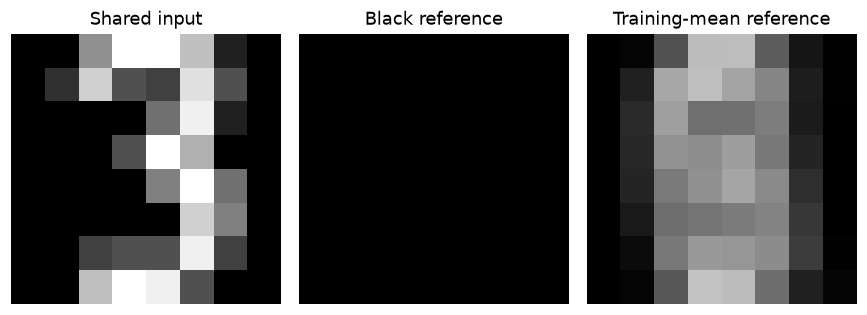

In [3]:
TARGET_CLASS = 3
query_position = int(np.flatnonzero(y_test == TARGET_CLASS)[0])
query = X_test[query_position:query_position+1].clone()
black = torch.zeros_like(query)
mean_image = X_train.mean(dim=0, keepdim=True)
regions = grid_regions(8, 8, 2)
N_REGIONS = int(regions.max()) + 1
with torch.no_grad():
    query_logits = model(query)[0]
    target_logit = float(query_logits[TARGET_CLASS])
    target_probability = float(query_logits.softmax(dim=0)[TARGET_CLASS])
print(f'Dataset row {test_ids[query_position]}, true digit {y_test[query_position]}, predicted digit {int(query_logits.argmax())}')
print(f'Fixed target {TARGET_CLASS}: logit={target_logit:.4f}, probability={target_probability:.4f}')
fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
for ax, values, title in zip(axes, [query[0,0], black[0,0], mean_image[0,0]],
                            ['Shared input', 'Black reference', 'Training-mean reference']):
    ax.imshow(values, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()

## Pixel gradients, path integration and noise averaging

- **Signed gradient** $\partial f_c/\partial x_i$ measures local sensitivity of the selected logit to normalized intensity.
- **Input × gradient** multiplies that derivative by the pixel value. For a nonlinear biased network it need not reconstruct the logit difference from black.
- **IG** integrates gradients along a straight path from a specified reference. We use a trapezoidal rule and check whether the contributions sum approximately to $f_c(x)-f_c(b)$.
- **SmoothGrad** averages signed gradients over 64 noisy copies (Gaussian standard deviation 0.10). Noise is **not clipped**; some perturbed inputs leave [0, 1], and none is guaranteed to be a natural digit.

IG is computed for both black and the training-mean image. Different references ask different questions. Numerical integration error is reported at multiple step counts; a smaller residual only checks reconstruction, not causal meaning. The helper functions keep the target class fixed along the full path.

In [4]:
gradient = input_gradients(model, query, TARGET_CLASS)[0,0].numpy()
input_times_gradient = query[0,0].numpy() * gradient
smooth_gradient = smooth_gradients(model, query, TARGET_CLASS, samples=64, noise_std=0.10, seed=SEED)[0,0].numpy()
ig_maps = {}
ig_checks = []
for reference_name, baseline in [('black', black), ('training mean', mean_image)]:
    with torch.no_grad():
        baseline_logit = float(model(baseline)[0, TARGET_CLASS])
    expected_difference = target_logit - baseline_logit
    for steps in [32, 128, 512]:
        values = integrated_gradients(model, query, baseline, TARGET_CLASS, num_steps=steps)[0,0].numpy()
        residual = float(values.sum() - expected_difference)
        ig_checks.append({'reference': reference_name, 'integration_steps': steps, 'reference_logit': baseline_logit,
                          'target_minus_reference': expected_difference, 'sum_attributions': float(values.sum()),
                          'signed_residual': residual, 'absolute_residual': abs(residual)})
        if steps == 512:
            ig_maps[reference_name] = values
            # Explicit coarse numerical guard; the table exposes the actual error.
            np.testing.assert_allclose(values.sum(), expected_difference, rtol=0.02, atol=0.02)
display(pd.DataFrame(ig_checks).round(5))

,reference,integration_steps,reference_logit,target_minus_reference,sum_attributions,signed_residual,absolute_residual
0,black,32,-0.14332,10.82741,10.75085,-0.07656,0.07656
1,black,128,-0.14332,10.82741,10.81767,-0.00974,0.00974
2,black,512,-0.14332,10.82741,10.82674,-0.00067,0.00067
3,training mean,32,-4.22080,14.90489,14.98525,0.08036,0.08036
4,training mean,128,-4.22080,14.90489,14.90699,0.00210,0.00210
5,training mean,512,-4.22080,14.90489,14.90457,-0.00032,0.00032


## Occlusion and Grad-CAM

**Occlusion** measures `original target logit − target logit with one 2×2 region blacked out`. Removing negative evidence can increase the score, producing a negative value. Individual removals are not additive when regions interact.

**Grad-CAM** averages target-logit gradients spatially within the last 16 feature channels, weights their activation maps, then applies ReLU. The native map is **4×4** and keeps only positive evidence under this construction. Bilinear upsampling to 8×8 is for display; it does not create pixel-level resolution or an additive decomposition.

A zero Grad-CAM map can occur when spatial gradient averaging and ReLU discard the response. It does **not** show that no pixels matter: inspect the derivatives, occlusion responses and the selected score. We retain this fixed case even when its map is uninformative.

In [5]:
occlusion = occlusion_scores(model, query, black, TARGET_CLASS, regions)
gradcam_native, gradcam_upsampled = grad_cam(model, query, TARGET_CLASS)
print('Grad-CAM native resolution:', gradcam_native.shape, '; displayed resolution:', gradcam_upsampled.shape)
assert gradcam_native.shape == (4, 4)
assert np.isfinite(gradcam_upsampled).all()
if np.max(gradcam_upsampled) == 0:
    print('Grad-CAM is all zero for this fixed case: no spatial ranking is available from this map.')

Grad-CAM native resolution: (4, 4) ; displayed resolution: (8, 8)
Grad-CAM is all zero for this fixed case: no spatial ranking is available from this map.


## SHAP and LIME on the same sixteen region-presence variables

Define `g(z)` as the CNN's **digit-3 logit** when regions with `z=1` are retained and regions with `z=0` are replaced by black. The CNN and target stay unchanged.

**Kernel SHAP** uses the all-absent mask as its reference and 512 sampled coalitions. Its sixteen contributions allocate the difference from the all-black score under this masking game. This is grouped SHAP, not pixel-level SHAP. Additivity is checked; sampling variability and the artificial masking distribution remain limitations.

**LIME** uses its tabular **regression** interface on binary region-presence features, allowing it to fit this same logit rather than switching to class probabilities. It samples a neighborhood and fits a regularized linear surrogate. Its weights, intercept, local R² and case approximation error describe that surrogate. This is a controlled region-mask use of LIME, not the library's default image segmentation pipeline. A good fit on masked images does not establish fidelity on natural digits.

In [6]:
def region_prediction(presence):
    presence = np.asarray(presence, dtype=np.float32)
    batches = []
    with torch.no_grad():
        for start in range(0, len(presence), 128):
            batch = masked_images(query, black, presence[start:start+128], regions)
            batches.append(model(batch)[:, TARGET_CLASS].numpy())
    return np.concatenate(batches)

all_present = np.ones((1, N_REGIONS), dtype=np.float32)
all_absent = np.zeros((1, N_REGIONS), dtype=np.float32)
np.testing.assert_allclose(region_prediction(all_present)[0], target_logit, rtol=1e-6)
np.random.seed(SEED)
region_shap_explainer = shap.KernelExplainer(region_prediction, all_absent, link='identity')
region_shap = np.asarray(region_shap_explainer.shap_values(all_present, nsamples=512, l1_reg=0, silent=True))[0]
shap_reference = float(region_shap_explainer.expected_value)
np.testing.assert_allclose(shap_reference + region_shap.sum(), target_logit, atol=1e-5)

# This is a synthetic mask distribution, not a background sample of real digits.
rng = np.random.default_rng(SEED)
mask_training = rng.integers(0, 2, size=(1024, N_REGIONS)).astype(np.float32)
lime_explainer = LimeTabularExplainer(mask_training, mode='regression',
                                    feature_names=[f'region {j}' for j in range(N_REGIONS)],
                                    categorical_features=list(range(N_REGIONS)),
                                    categorical_names={j: ['absent', 'present'] for j in range(N_REGIONS)},
                                    discretize_continuous=False, feature_selection='none', random_state=SEED)
region_lime_explanation = lime_explainer.explain_instance(all_present[0], region_prediction,
                                                       num_features=N_REGIONS, num_samples=2048)
# LIME stores the positive regression explanation under key 1.
region_lime = np.zeros(N_REGIONS)
for region_id, weight in region_lime_explanation.local_exp[1]:
    region_lime[region_id] = weight
lime_prediction = float(region_lime_explanation.local_pred[0])
lime_intercept = float(region_lime_explanation.intercept[1])
np.testing.assert_allclose(lime_intercept + region_lime.sum(), lime_prediction, atol=1e-6)
display(pd.Series({'target_logit': target_logit, 'black_reference_logit': shap_reference,
                   'SHAP_reconstruction_absolute_error': abs(shap_reference+region_shap.sum()-target_logit),
                   'LIME_neighborhood_R2': region_lime_explanation.score,
                   'LIME_case_absolute_logit_gap': abs(lime_prediction-target_logit)}, name='region checks'))

target_logit                          10.684091
black_reference_logit                 -0.143324
SHAP_reconstruction_absolute_error     0.000000
LIME_neighborhood_R2                   0.970583
LIME_case_absolute_logit_gap           0.701553
Name: region checks, dtype: float64

## Compare the pictures without comparing incompatible magnitudes

Each attribution panel is scaled by **its own maximum absolute value**, preserving sign: orange means positive, blue means negative. The displayed numbers are normalized to [-1, 1] for legibility, not a common physical unit. Grad-CAM is nonnegative. Original scales and resolutions are listed below.

A region's SHAP/LIME/occlusion value is repeated across its four pixels only to visualize its location: **do not sum the repeated map as though each pixel held a separate contribution**. IG with the training-mean baseline has a different reference from the black-baseline methods.

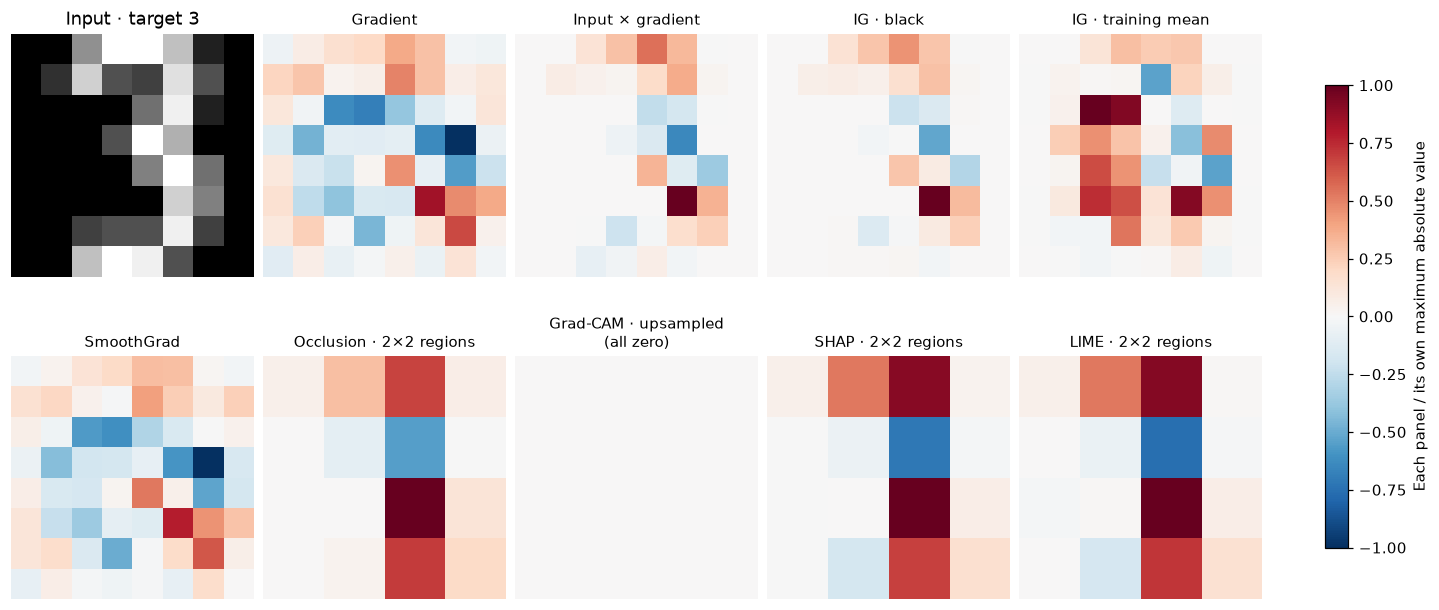

,original units,resolution,original max |value|
method,,,
Gradient,logit / normalized intensity,8×8 pixels,6.089676
Input × gradient,logit-scale first-order term,8×8 pixels,4.152130
IG · black,logit contribution,8×8 pixels,4.320641
IG · training mean,logit contribution,8×8 pixels,1.883636
SmoothGrad,mean logit derivative,8×8 pixels,6.246175
Occlusion · 2×2 regions,logit difference per region,4×4 regions,5.469095
Grad-CAM · upsampled,activation-weighted localization score,4×4 activations → 8×8 display,0.000000
SHAP · 2×2 regions,logit contribution per region,4×4 regions,4.417704
LIME · 2×2 regions,local surrogate logit coefficient per region,4×4 regions,4.299993


In [7]:
maps = {
    'Gradient': gradient,
    'Input × gradient': input_times_gradient,
    'IG · black': ig_maps['black'],
    'IG · training mean': ig_maps['training mean'],
    'SmoothGrad': smooth_gradient,
    'Occlusion · 2×2 regions': occlusion[regions],
    'Grad-CAM · upsampled': gradcam_upsampled,
    'SHAP · 2×2 regions': region_shap[regions],
    'LIME · 2×2 regions': region_lime[regions],
}
def normalized_for_display(values):
    scale = float(np.abs(values).max())
    return values / scale if scale > 0 else np.zeros_like(values)

fig, axes = plt.subplots(2, 5, figsize=(13, 5.7), layout='constrained')
axes.flat[0].imshow(query[0,0], cmap='gray', vmin=0, vmax=1)
axes.flat[0].set_title(f'Input · target {TARGET_CLASS}')
axes.flat[0].axis('off')
for ax, (name, values) in zip(list(axes.flat)[1:], maps.items()):
    im = ax.imshow(normalized_for_display(values), cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
    ax.set_title(name if np.abs(values).max() > 0 else name + '\n(all zero)', fontsize=10)
    ax.axis('off')
fig.colorbar(im, ax=list(axes.flat), shrink=0.75, label='Each panel / its own maximum absolute value')
plt.show()

units = ['logit / normalized intensity', 'logit-scale first-order term', 'logit contribution', 'logit contribution',
         'mean logit derivative', 'logit difference per region', 'activation-weighted localization score',
         'logit contribution per region', 'local surrogate logit coefficient per region']
resolutions = ['8×8 pixels'] * 5 + ['4×4 regions', '4×4 activations → 8×8 display', '4×4 regions', '4×4 regions']
display(pd.DataFrame({'method': list(maps), 'original units': units, 'resolution': resolutions,
                      'original max |value|': [float(np.abs(value).max()) for value in maps.values()]}).set_index('method'))

## Sanity control: randomize the model, keep the input and target

Initialize a second CNN of the same architecture with fresh random weights and **do not train it**. Compare its IG and Grad-CAM with the trained model's maps for the original digit-3 logit. We do not switch to the random model's predicted class.

This is a simple full-parameter randomization control, not the full cascading/data-randomization study. Rank correlation of absolute map values checks whether the spatial ranking changes; a constant map has undefined correlation. A changing map indicates parameter sensitivity in this experiment, not proof of faithfulness or human usefulness. Similar-looking maps may arise from architecture or input structure and require further investigation.

In particular, input × gradient and black-baseline IG multiply by the input itself. Pixels that are zero stay zero even in a randomized model, so a high absolute-rank correlation can partly reflect shared input structure. This is a reason to investigate further, not a result to hide by selecting a different image.

Random model predicts 5; fixed target remains 3; its target logit is 0.0117


IG absolute-rank correlation          0.894365
Grad-CAM absolute-rank correlation         NaN
Name: trained vs random model, dtype: float64

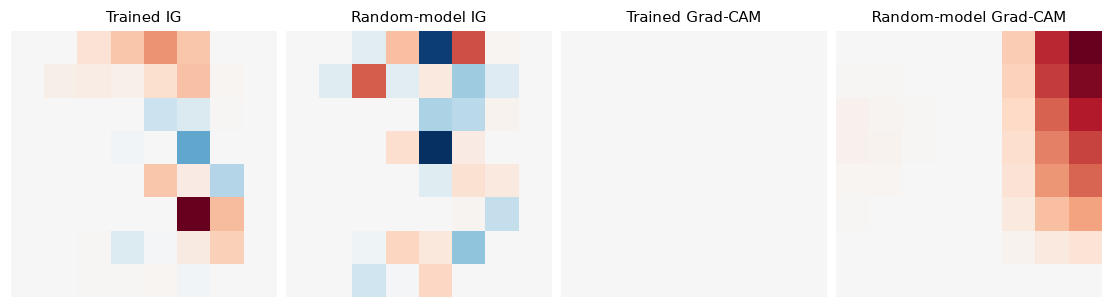

In [8]:
with torch.random.fork_rng():
    torch.manual_seed(SEED + 1)
    random_model = DigitCNN().eval()
random_ig = integrated_gradients(random_model, query, black, TARGET_CLASS, num_steps=512)[0,0].numpy()
_, random_cam = grad_cam(random_model, query, TARGET_CLASS)
def absolute_rank_correlation(left, right):
    a, b = np.abs(left).ravel(), np.abs(right).ravel()
    return float(spearmanr(a, b).statistic) if np.ptp(a) > 0 and np.ptp(b) > 0 else np.nan

with torch.no_grad():
    random_logits = random_model(query)[0]
print(f'Random model predicts {int(random_logits.argmax())}; fixed target remains {TARGET_CLASS}; its target logit is {float(random_logits[TARGET_CLASS]):.4f}')
display(pd.Series({'IG absolute-rank correlation': absolute_rank_correlation(ig_maps['black'], random_ig),
                   'Grad-CAM absolute-rank correlation': absolute_rank_correlation(gradcam_upsampled, random_cam)},
                  name='trained vs random model'))
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), layout='constrained')
for ax, values, title in zip(axes, [ig_maps['black'], random_ig, gradcam_upsampled, random_cam],
                            ['Trained IG', 'Random-model IG', 'Trained Grad-CAM', 'Random-model Grad-CAM']):
    ax.imshow(normalized_for_display(values), cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.show()

## Region-removal check versus random ordering

Make all rankings use the same sixteen 2×2 regions. For pixel maps, sum absolute pixel scores within each region; for SHAP/LIME/occlusion use the absolute region score. Rank Grad-CAM using its upsampled absolute scores. Remove regions in descending rank, replace them by black, and report the **original target logit minus the masked target logit**. The mean and standard deviation over 30 random orders provide a reference.

This checks sensitivity to a stated masking operation, not a universal measure of explanation quality. Removing negative evidence can increase the logit, giving a negative drop. Masked images can leave the data distribution, the model is not retrained, black and region size influence results, and some methods directly optimize related masking questions. No area-under-curve winner is declared from this one example.

Constant maps have no evidence-based region ordering and are excluded rather than assigning importance by an arbitrary tie-break. The training-mean IG variant is also omitted from this primary black-reference comparison.

No ranking available for constant maps: ['Grad-CAM']


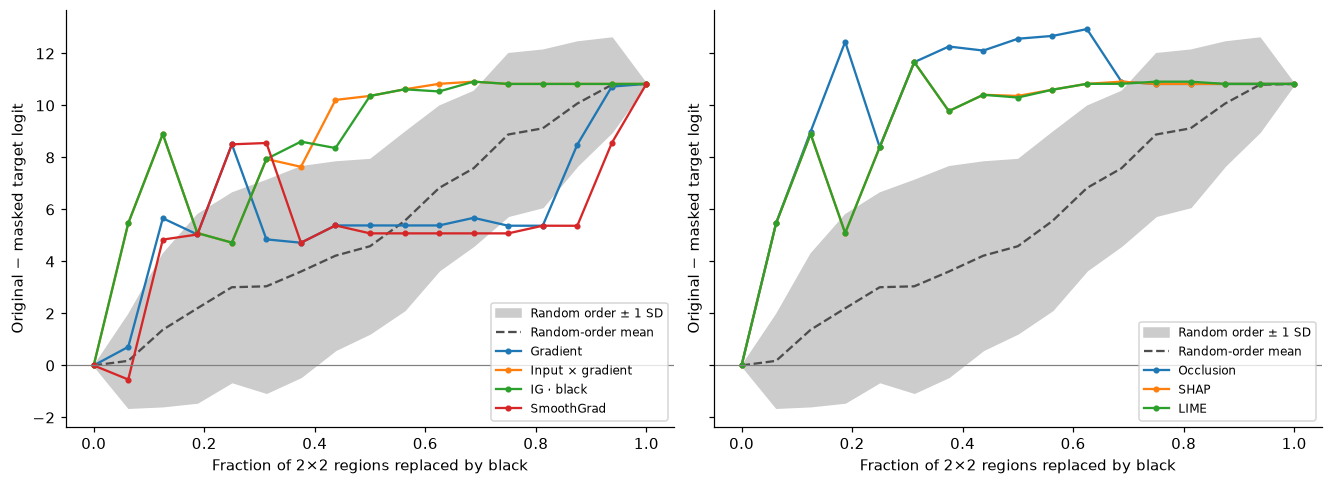

In [9]:
def aggregate_absolute_pixels(values):
    return np.array([np.abs(values)[regions == j].sum() for j in range(N_REGIONS)])

region_scores = {
    'Gradient': aggregate_absolute_pixels(gradient),
    'Input × gradient': aggregate_absolute_pixels(input_times_gradient),
    'IG · black': aggregate_absolute_pixels(ig_maps['black']),
    'SmoothGrad': aggregate_absolute_pixels(smooth_gradient),
    'Occlusion': np.abs(occlusion),
    'Grad-CAM': aggregate_absolute_pixels(gradcam_upsampled),
    'SHAP': np.abs(region_shap),
    'LIME': np.abs(region_lime),
}
def removal_curve(order):
    masks = np.ones((N_REGIONS + 1, N_REGIONS), dtype=np.float32)
    for count in range(1, N_REGIONS + 1):
        masks[count, order[:count]] = 0
    return target_logit - region_prediction(masks)

uninformative = [name for name, scores in region_scores.items() if np.ptp(scores) < 1e-12]
print('No ranking available for constant maps:', uninformative or 'none')
curves = {name: removal_curve(np.argsort(-scores, kind='stable'))
          for name, scores in region_scores.items() if name not in uninformative}
rng = np.random.default_rng(SEED)
random_curves = np.array([removal_curve(rng.permutation(N_REGIONS)) for _ in range(30)])
random_mean, random_sd = random_curves.mean(axis=0), random_curves.std(axis=0)
fraction = np.arange(N_REGIONS + 1) / N_REGIONS
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True, layout='constrained')
for ax, names in zip(axes, [list(curves)[:4], list(curves)[4:]]):
    ax.fill_between(fraction, random_mean-random_sd, random_mean+random_sd, color='0.8', label='Random order ± 1 SD')
    ax.plot(fraction, random_mean, '--', color='0.3', label='Random-order mean')
    for name in names:
        ax.plot(fraction, curves[name], marker='.', label=name)
    ax.axhline(0, color='0.5', linewidth=0.8)
    ax.set(xlabel='Fraction of 2×2 regions replaced by black', ylabel='Original − masked target logit')
    ax.legend(fontsize=8)
plt.show()
# Every ordering begins with the original input and ends with the same black input.
for curve in [*curves.values(), *random_curves]:
    np.testing.assert_allclose(curve[0], 0, atol=1e-5)
    np.testing.assert_allclose(curve[-1], target_logit-shap_reference, atol=1e-5)

## Interpretation and extensions

The shared target removes one source of comparison confusion, but these methods still answer distinct questions. Derivatives describe local sensitivity; IG and SHAP allocate a reference difference under different definitions; LIME approximates a neighborhood; occlusion measures a particular removal; Grad-CAM localizes coarse positive evidence. Attractive or agreeing maps alone do not validate those claims.

Before generalizing, repeat across correctly and incorrectly classified cases, classes, training seeds, references, region sizes and datasets. Evaluate the downstream task the explanation is intended to support. DeepLIFT, LRP, attention-specific explanations and concept-based methods are **not implemented here**; they require additional choices beyond this introductory comparison.

## Primary references and provenance

- Dataset: [scikit-learn digits loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), derived from the UCI optical recognition dataset, with 8×8 integer-intensity images.
- Gradient saliency: [Simonyan, Vedaldi and Zisserman](https://arxiv.org/abs/1312.6034).
- Integrated Gradients: [Sundararajan, Taly and Yan](https://arxiv.org/abs/1703.01365).
- SmoothGrad: [Smilkov et al.](https://arxiv.org/abs/1706.03825).
- Occlusion-based inspection: [Zeiler and Fergus](https://arxiv.org/abs/1311.2901).
- Grad-CAM: [Selvaraju et al.](https://arxiv.org/abs/1610.02391).
- SHAP: [Lundberg and Lee](https://arxiv.org/abs/1705.07874); LIME: [Ribeiro, Singh and Guestrin](https://arxiv.org/abs/1602.04938).
- Randomization checks: [Adebayo et al., NeurIPS 2018](https://proceedings.neurips.cc/paper/2018/hash/294a8ed24b1ad22ec2e7efea049b8737-Abstract.html).

In [10]:
print(f'Calculation time after imports: {time.perf_counter()-started:.1f} seconds')
print('All explanation targets remained fixed at digit', TARGET_CLASS)

Calculation time after imports: 2.7 seconds
All explanation targets remained fixed at digit 3
